<div dir="rtl">

# مشروع صغير: تحليل طلبات مطعم بمساعدة الذكاء الاصطناعي
**السؤال الرئيسي:** أين تربح إدارة المطعم، ومتى يزدحم، وما الذي يُغضب العملاء؟

**البيانات:** `restaurant_orders.csv` (طلبات 3 فروع، يناير إلى يونيو 2025). اقرأ `data_dictionary_restaurant.md` أولًا.

**المهارات المستخدمة في Cursor:** `/data-quality-report` ← `/kpi-summary` ← `/clear-charts` ← `/insight-report`

**طريقة العمل:** لكل سؤال: اطلب من Agent الكود (أو استدعِ المهارة)، اقرأ الكود قبل قبوله، شغّله، ثم قارن بنقطة التحقق.

</div>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("restaurant_orders.csv")
print(df.shape)   # نقطة تحقق: (1515, 12)
df.head()

(1515, 12)


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 1: فحص الجودة والتنظيف
في Agent: `/data-quality-report افحص restaurant_orders.csv` ثم: «نظّف البيانات حسب التقرير واحفظها في clean».

**نقطة تحقق:** 15 صفًا مكررًا، و6 كتابات مختلفة لأسماء الفروع، و136 تقييمًا مفقودًا. بعد التنظيف: **1500 صف** و3 فروع فقط.

### تقرير جودة البيانات
| المشكلة | العمود | عدد الصفوف | اقتراح المعالجة |
| --- | --- | ---: | --- |
| صفوف مكررة بالكامل | جميع الأعمدة | 15 | مراجعة السجلات ثم حذف النسخ المطابقة والإبقاء على سجل واحد. |
| كتابة غير موحدة (6 صيغ غير معيارية) | branch | 24 | إزالة المسافات الزائدة وتوحيد حالة الأحرف ثم مطابقة الأسماء مع الفروع الثلاثة المعتمدة. |
| تقييمات مفقودة | rating | 136 | عدم حذف الصفوف؛ استبعاد القيم المفقودة فقط عند حساب متوسط التقييم. |

> القيم المفقودة في `delivery_minutes` طبيعية للطلبات غير الخاصة بالتوصيل، فلا تُعد مشكلة. لا توجد قيم سالبة في الأعمدة الرقمية. لم يُعدّل ملف CSV الأصلي.

</div>

In [3]:
import pandas as pd
from IPython.display import display, Markdown

# فحص جودة البيانات دون تعديل الملف الأصلي
print("الأبعاد (صفوف، أعمدة):", df.shape)
print("\nأنواع الأعمدة:\n", df.dtypes.to_string())
print("\nالقيم المفقودة في كل عمود:\n", df.isna().sum().to_string())
print("\nعدد الصفوف المكررة بالكامل:", int(df.duplicated().sum()))

print("\nالقيم المختلفة للأعمدة النصية التي لديها أقل من 20 قيمة:")
text_columns = [column for column in df.columns if pd.api.types.is_string_dtype(df[column].dtype)]
for column in text_columns:
    values = sorted(df[column].dropna().unique().tolist())
    if len(values) < 20:
        print(f"{column} ({len(values)}): {values}")

print("\nالنطاق العددي وفحص القيم السالبة:")
for column in df.select_dtypes(include="number").columns:
    values = df[column].dropna()
    print(f"{column}: الأصغر={values.min()}, الأكبر={values.max()}, السوالب={int((values < 0).sum())}")

branch_canonical = df["branch"].str.strip().str.title()
branch_variant_rows = int((df["branch"] != branch_canonical).sum())
branch_variant_spellings = int(df.loc[df["branch"] != branch_canonical, "branch"].nunique())
report = pd.DataFrame([
    {
        "المشكلة": "صفوف مكررة بالكامل",
        "العمود": "جميع الأعمدة",
        "عدد الصفوف": int(df.duplicated().sum()),
        "اقتراح المعالجة": "مراجعة السجلات المكررة ثم حذف النسخ المطابقة والإبقاء على سجل واحد."
    },
    {
        "المشكلة": f"كتابة غير موحدة لأسماء الفروع ({branch_variant_spellings} صيغ غير معيارية)",
        "العمود": "branch",
        "عدد الصفوف": branch_variant_rows,
        "اقتراح المعالجة": "إزالة المسافات الزائدة وتوحيد حالة الأحرف ثم مطابقة الأسماء مع الفروع الثلاثة المعتمدة."
    },
    {
        "المشكلة": "تقييمات مفقودة",
        "العمود": "rating",
        "عدد الصفوف": int(df["rating"].isna().sum()),
        "اقتراح المعالجة": "عدم حذف الصفوف؛ استبعاد التقييمات المفقودة فقط عند حساب متوسط التقييم."
    }
])
display(Markdown("## تقرير جودة البيانات\n\n> القيم المفقودة في `delivery_minutes` طبيعية للطلبات غير الخاصة بالتوصيل، لذلك لا تُعد مشكلة. لم يُعدّل ملف البيانات.\n"))
display(report)

# تجهيز نسخة منظّفة للتحليل مع إبقاء df وملف CSV دون تغيير
clean = df.drop_duplicates().copy()
clean["branch"] = clean["branch"].str.strip().str.title()
print("\nبعد التنظيف:", clean.shape, "| الفروع:", sorted(clean["branch"].unique()))


الأبعاد (صفوف، أعمدة): (1515, 12)

أنواع الأعمدة:
 order_id                str
order_date              str
order_hour            int64
branch                  str
channel                 str
category                str
item                    str
quantity              int64
unit_price          float64
total               float64
delivery_minutes    float64
rating              float64

القيم المفقودة في كل عمود:
 order_id               0
order_date             0
order_hour             0
branch                 0
channel                0
category               0
item                   0
quantity               0
unit_price             0
total                  0
delivery_minutes    1137
rating               136

عدد الصفوف المكررة بالكامل: 15

القيم المختلفة للأعمدة النصية التي لديها أقل من 20 قيمة:
branch (9): [' downtown', ' mall', ' university', 'DOWNTOWN', 'Downtown', 'MALL', 'Mall', 'UNIVERSITY', 'University']
channel (3): ['Delivery', 'Dine-in', 'Takeaway']
category (4): ['Dessert', '

## تقرير جودة البيانات

> القيم المفقودة في `delivery_minutes` طبيعية للطلبات غير الخاصة بالتوصيل، لذلك لا تُعد مشكلة. لم يُعدّل ملف البيانات.


,المشكلة,العمود,عدد الصفوف,اقتراح المعالجة
0,صفوف مكررة بالكامل,جميع الأعمدة,15,مراجعة السجلات المكررة ثم حذف النسخ المطابقة و...
1,كتابة غير موحدة لأسماء الفروع (6 صيغ غير معيارية),branch,24,إزالة المسافات الزائدة وتوحيد حالة الأحرف ثم م...
2,تقييمات مفقودة,rating,136,عدم حذف الصفوف؛ استبعاد التقييمات المفقودة فقط...



بعد التنظيف: (1500, 12) | الفروع: ['Downtown', 'Mall', 'University']


<div dir="rtl">

## الخطوة 2: مؤشرات الأداء (س1)
**س1:** ما إجمالي الإيرادات وعدد الطلبات ومتوسط قيمة الطلب ومتوسط التقييم؟ وما هي لكل فرع؟

في Agent: `/kpi-summary احسب المؤشرات العامة ثم قارن الفروع`

</div>

In [4]:
from IPython.display import display, Markdown

total_revenue = clean["total"].sum()
order_count = clean["order_id"].nunique()
average_order_value = total_revenue / order_count
average_rating = clean["rating"].mean()

overall_kpis = pd.DataFrame([{
    "إجمالي الإيرادات ($)": total_revenue,
    "عدد الطلبات": order_count,
    "متوسط قيمة الطلب ($)": average_order_value,
    "متوسط التقييم": average_rating
}]).round(2)
display(Markdown("### المؤشرات العامة"))
display(overall_kpis)

branch_kpis = clean.groupby("branch").agg(
    الإيرادات=("total", "sum"),
    عدد_الطلبات=("order_id", "nunique"),
    متوسط_التقييم=("rating", "mean")
)
branch_kpis["متوسط_قيمة_الطلب"] = branch_kpis["الإيرادات"] / branch_kpis["عدد_الطلبات"]
branch_kpis["النسبة_من_الإجمالي_%"] = branch_kpis["الإيرادات"] / total_revenue * 100
branch_kpis = branch_kpis.sort_values("الإيرادات", ascending=False)
branch_display = branch_kpis.rename(columns={
    "الإيرادات": "الإيرادات ($)",
    "عدد_الطلبات": "عدد الطلبات",
    "متوسط_التقييم": "متوسط التقييم",
    "متوسط_قيمة_الطلب": "متوسط قيمة الطلب ($)",
    "النسبة_من_الإجمالي_%": "النسبة من الإجمالي %"
}).round(2)
display(Markdown("### مقارنة الفروع"))
display(branch_display)

assert abs(branch_kpis["الإيرادات"].sum() - total_revenue) < 1e-9
print(f"تحقق الإيرادات: مجموع إيرادات الفروع = الإجمالي العام (${branch_kpis['الإيرادات'].sum():,.2f}).")

highest_branch = branch_kpis["الإيرادات"].idxmax()
lowest_branch = branch_kpis["الإيرادات"].idxmin()
revenue_difference = branch_kpis.loc[highest_branch, "الإيرادات"] - branch_kpis.loc[lowest_branch, "الإيرادات"]
display(Markdown(
    f"أعلى مجموعة: {highest_branch} بإيرادات ${branch_kpis.loc[highest_branch, 'الإيرادات']:,.2f}.  \n"
    f"أقل مجموعة: {lowest_branch} بإيرادات ${branch_kpis.loc[lowest_branch, 'الإيرادات']:,.2f}.  \n"
    f"الفرق بينهما: ${revenue_difference:,.2f}."
))


### المؤشرات العامة

,إجمالي الإيرادات ($),عدد الطلبات,متوسط قيمة الطلب ($),متوسط التقييم
0,18751.0,1500,12.5,4.07


### مقارنة الفروع

,الإيرادات ($),عدد الطلبات,متوسط التقييم,متوسط قيمة الطلب ($),النسبة من الإجمالي %
branch,,,,,
Mall,7933.0,590,4.12,13.45,42.31
Downtown,6678.0,466,4.01,14.33,35.61
University,4140.0,444,4.04,9.32,22.08


تحقق الإيرادات: مجموع إيرادات الفروع = الإجمالي العام ($18,751.00).


أعلى مجموعة: Mall بإيرادات $7,933.00.  
أقل مجموعة: University بإيرادات $4,140.00.  
الفرق بينهما: $3,793.00.

<div dir="rtl">

## الخطوة 3: الذروة والقنوات والأصناف (س2، س3، س4)
- **س2:** ما ساعات الذروة؟ وأي أيام الأسبوع أكثر ازدحامًا؟
- **س3:** ما حصة كل قناة (صالة، سفري، توصيل) من الإيرادات؟
- **س4:** ما أعلى 5 أصناف من حيث الإيرادات؟

ارسم رسمين على الأقل باستخدام `/clear-charts`.

</div>

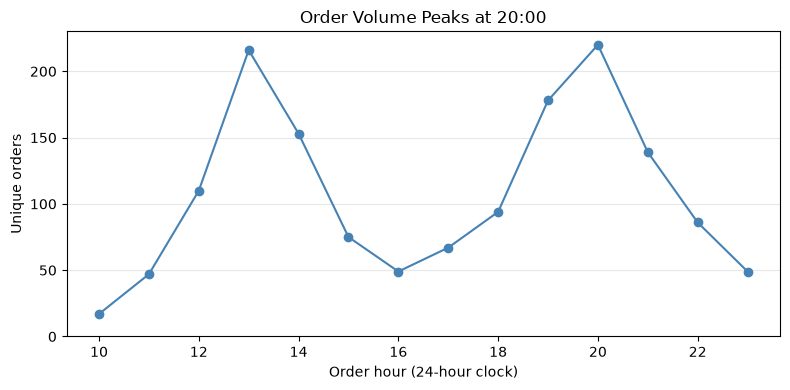

Unique orders by hour:


,Unique orders
order_hour,
10,17
11,47
12,110
13,216
14,153
15,75
16,49
17,67
18,94


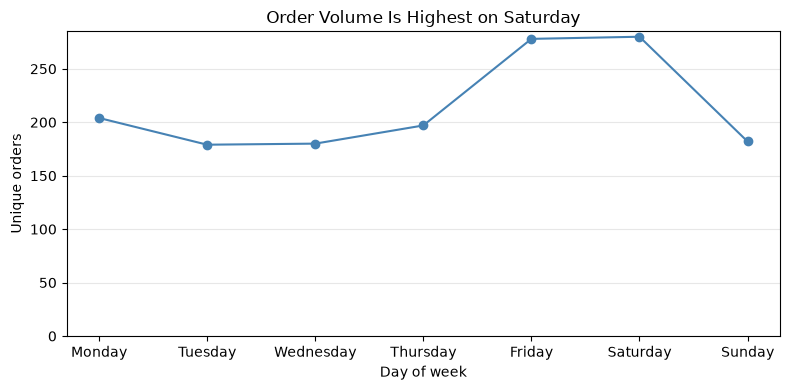

Unique orders by weekday:


,Unique orders
weekday,
Monday,204
Tuesday,179
Wednesday,180
Thursday,197
Friday,278
Saturday,280
Sunday,182


In [5]:
# الطلبات حسب الساعة ويوم الأسبوع
import matplotlib.pyplot as plt

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hourly_orders = clean.groupby("order_hour")["order_id"].nunique().sort_index()
daily_orders = clean.assign(weekday=pd.to_datetime(clean["order_date"]).dt.day_name()).groupby("weekday")["order_id"].nunique().reindex(weekday_order)

fig, ax = plt.subplots(figsize=(8, 4))
hourly_orders.plot(kind="line", marker="o", color="steelblue", ax=ax)
ax.set(title="Order Volume Peaks at 20:00", xlabel="Order hour (24-hour clock)", ylabel="Unique orders")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
print("Unique orders by hour:")
display(hourly_orders.rename("Unique orders").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
daily_orders.plot(kind="line", marker="o", color="steelblue", ax=ax)
ax.set(title="Order Volume Is Highest on Saturday", xlabel="Day of week", ylabel="Unique orders")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
print("Unique orders by weekday:")
display(daily_orders.rename("Unique orders").to_frame())


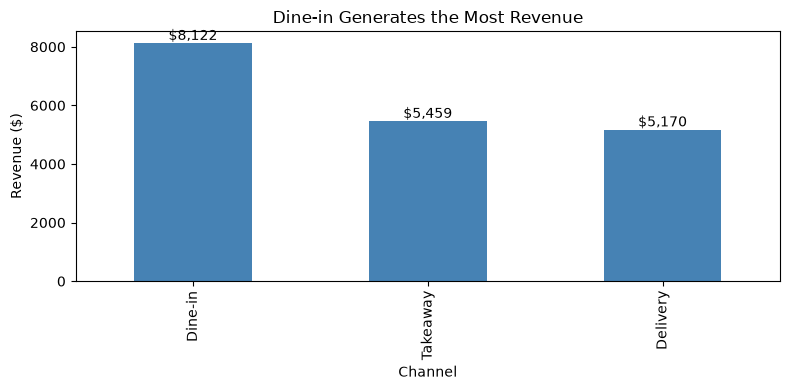

Revenue and share by channel:


,Revenue ($),Revenue share (%)
channel,,
Dine-in,8122.0,43.32
Takeaway,5459.0,29.11
Delivery,5170.0,27.57


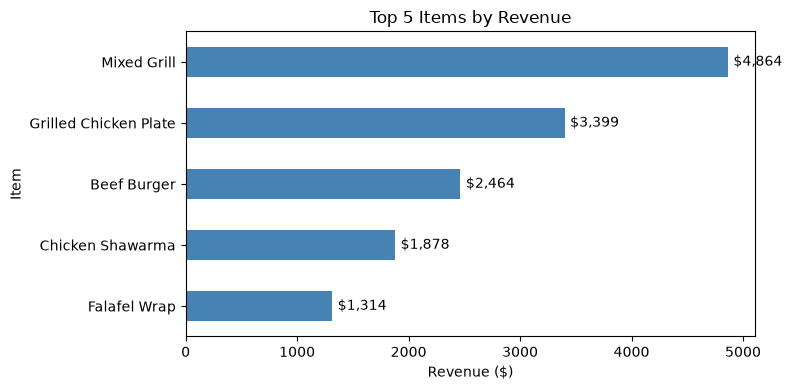

Top 5 items by revenue:


,Revenue ($)
item,
Mixed Grill,4864.0
Grilled Chicken Plate,3399.0
Beef Burger,2464.0
Chicken Shawarma,1878.5
Falafel Wrap,1314.0


In [6]:
# إيرادات القنوات وأعلى خمسة أصناف
channel_revenue = clean.groupby("channel")["total"].sum().sort_values(ascending=False)
channel_share = (channel_revenue / clean["total"].sum() * 100).rename("Revenue share (%)")
channel_summary = pd.concat([channel_revenue.rename("Revenue ($)"), channel_share], axis=1).round(2)

fig, ax = plt.subplots(figsize=(8, 4))
channel_revenue.plot(kind="bar", color="steelblue", ax=ax)
ax.set(title="Dine-in Generates the Most Revenue", xlabel="Channel", ylabel="Revenue ($)")
ax.set_ylim(bottom=0)
for bar in ax.patches:
    ax.annotate(f"${bar.get_height():,.0f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom")
fig.tight_layout()
plt.show()
print("Revenue and share by channel:")
display(channel_summary)

top_items = clean.groupby("item")["total"].sum().sort_values(ascending=False).head(5)
fig, ax = plt.subplots(figsize=(8, 4))
top_items.sort_values().plot(kind="barh", color="steelblue", ax=ax)
ax.set(title="Top 5 Items by Revenue", xlabel="Revenue ($)", ylabel="Item")
ax.set_xlim(left=0)
for bar in ax.patches:
    ax.annotate(f"${bar.get_width():,.0f}", (bar.get_width(), bar.get_y() + bar.get_height() / 2), va="center", xytext=(4, 0), textcoords="offset points")
fig.tight_layout()
plt.show()
print("Top 5 items by revenue:")
display(top_items.rename("Revenue ($)").to_frame().round(2))


<div dir="rtl">

## الخطوة 4: رضا العملاء (س5)
**س5:** هل يرتبط وقت التوصيل بتقييم العميل؟
قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة.

> هذه مقارنة بين متوسطات، لا تحتاج أي نموذج تعلم آلي. لكنها لا تثبت السبب وحدها.

</div>

In [10]:

# نستخدم طلبات التوصيل ذات المدة المسجلة فقط؛ وتُستبعد التقييمات المفقودة تلقائيًا عند حساب المتوسط.
delivery_orders = clean.loc[
    clean["channel"].eq("Delivery") & clean["delivery_minutes"].notna()
].copy()

labels = ["أقل من 30 دقيقة", "من 30 إلى 45 دقيقة", "أكثر من 45 دقيقة"]
delivery_minutes = delivery_orders["delivery_minutes"]
delivery_orders["فئة وقت التوصيل"] = pd.Series(index=delivery_orders.index, dtype="object")
delivery_orders.loc[delivery_minutes < 30, "فئة وقت التوصيل"] = labels[0]
delivery_orders.loc[
    delivery_minutes.ge(30) & delivery_minutes.le(45), "فئة وقت التوصيل"
] = labels[1]
delivery_orders.loc[delivery_minutes > 45, "فئة وقت التوصيل"] = labels[2]
delivery_orders["فئة وقت التوصيل"] = pd.Categorical(
    delivery_orders["فئة وقت التوصيل"], categories=labels, ordered=True
)

rating_by_delivery_time = (
    delivery_orders.groupby("فئة وقت التوصيل", observed=False)
    .agg(
        عدد_الطلبات=("order_id", "size"),
        متوسط_التقييم=("rating", "mean"),
    )
)

display(rating_by_delivery_time.round(2))


,عدد_الطلبات,متوسط_التقييم
فئة وقت التوصيل,,
أقل من 30 دقيقة,69,4.11
من 30 إلى 45 دقيقة,200,3.59
أكثر من 45 دقيقة,105,2.47


<div dir="rtl">

## الخطوة 5: الرؤى والتوصيات (س6)
في Agent: `/insight-report اكتب الرؤى والتوصيات من نتائج هذا الدفتر واحفظها في insights.md`

ثم راجع: هل كل رقم في التقرير موجود فعلًا في مخرجات الدفتر؟ سجّل أي خطأ في سجل التحقق أدناه.

## سجل التحقق
| ماذا قال الذكاء الاصطناعي | كيف تحققت | النتيجة |


|    فحص الجودة والتنظيف   | نفذ التقرير المطلوب في ملف data-quality  |    نقطة التحقق صحيح |


|   مؤشرات الأداء    |   kpi-summary احسب المؤشرات العامة ثم قارن الفروع  |   نقطة التحقق صحيح |

|   الذروة والقنوات والأصناف  |ارسم رسمين على الأقل باستخدام clear-charts  |   نقطة التحقق صحيح |

| رضا العملاء  |في الخلية المحددة قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة. |   نقطة التحقق صحيح |

|   الرؤى والتوصيات  | انشا ملف جديد اسمه insight.md -
-نفذ المهام المطلوبة في ملف @insight-repot  وضعها في ملف insight.md  |   نقطة التحقق صحيح |

</div>